1.2247448713915892


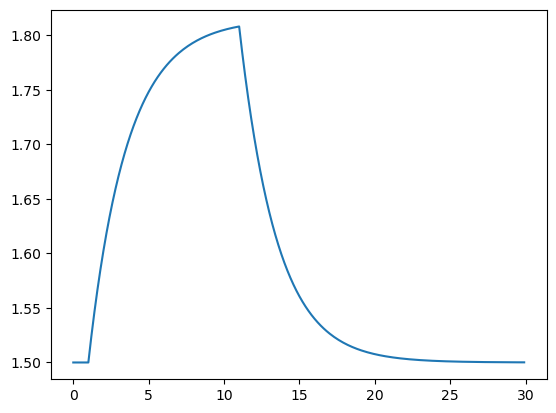

2.3999999999999995
1.6331367131729913
1.8033860478127928
43.883597855872566


In [22]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import odeint
from scipy.interpolate import interp1d
tstop=30.
tinc=0.1
t = np.arange(0.,tstop,tinc) ## initializing arrays for time
#
#initializing array of level and flow in
hts=1.5             #initial steady state value
fins=1.5            #initial flowrate in
area=1.2            #cross section area of vessel
k=fins/np.sqrt(hts)   #flow-level relation constant fo=k.sqrt(ht)
print(k)
# bundle parameters for ODE solver
params=[hts,fins,area,k] 
#
#defining derivatives from the ODE for pulse change in input flow
def flevel(ht,t,params):
    if t<=1 :
        fin=fins
    else:
        fin=1.1*fins #10% pulse change in flow in between time 1 to 2
    if t>11:
        fin=fins          
    level=ht
    dhdt=(fin/area)-k*np.sqrt(level)/area
    #print(t,level,dhdt)
    return dhdt
#
#define initial values of level
ht0=hts
#
# calling odeint; the ODE solver
ht=odeint(flevel, ht0, t, args=(params,))
# plotting the data
plt.plot(t, ht)
plt.show()
h1 = ht.flatten()
f = interp1d(t, h1)
tau = area*2*np.sqrt(hts)/k
print(tau)
h_tau = f(tau)
print(h_tau)
hf = f(4*tau)
print(hf)
print(100*(h_tau-hts)/(hf - hts))